# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np

# Fazendo o download da versão mais recente do Airbnb Open Data
path = kagglehub.dataset_download("arianazmoudeh/airbnbopendata")

print("Caminho para os arquivos do dataset:", path)

# O arquivo principal costuma se chamar 'Airbnb_Open_Data.csv'
file_path = os.path.join(path, 'Airbnb_Open_Data.csv')

try:
    df = pd.read_csv(file_path, low_memory=False)
    print("Dataset carregado com sucesso!")
    display(df.head())
except Exception as e:
    print(f"Erro ao carregar o arquivo: {e}")
    # Listar arquivos para ajudar na depuração se o nome for diferente
    print("Arquivos no diretório:", os.listdir(path))

100%|██████████| 10.5M/10.5M [00:01<00:00, 6.93MB/s]

Extracting files...


Caminho para os arquivos do dataset: /root/.cache/kagglehub/datasets/arianazmoudeh/airbnbopendata/versions/1
Dataset carregado com sucesso!


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,7/5/2019,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


### Adaptando o Princípio Estrutural para o Airbnb

O dataset do Airbnb contém informações sobre listagens, incluindo localização, preço, política de cancelamento e avaliações. Vamos verificar as dimensões e os tipos de dados originais.

In [ ]:
# Separando as variáveis conforme a natureza dos dados do Airbnb
VARS_QUANT = [
    'lat', 'long', 'Construction year', 'price', 'service fee',
    'minimum nights', 'number of reviews', 'reviews per month',
    'review rate number', 'calculated host listings count', 'availability 365'
]

VARS_QUALI = [
    'neighbourhood group', 'neighbourhood', 'room type',
    'cancellation_policy', 'host_identity_verified', 'instant_bookable'
]

# Limpeza de strings para numérico realizada anteriormente para garantir o tipo float
for col in ['price', 'service fee']:
    if col in df.columns and df[col].dtype == 'object':
        df[col] = df[col].replace('[\\$,]', '', regex=True).astype(float)

print("Variáveis Quantitativas:", VARS_QUANT)
print("Variáveis Qualitativas:", VARS_QUALI)
df[VARS_QUANT].info()

Variáveis Quantitativas: ['lat', 'long', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365']
Variáveis Qualitativas: ['neighbourhood group', 'neighbourhood', 'room type', 'cancellation_policy', 'host_identity_verified', 'instant_bookable']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 11 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   lat                             102591 non-null  float64
 1   long                            102591 non-null  float64
 2   Construction year               102385 non-null  float64
 3   price                           102352 non-null  float64
 4   service fee                     102326 non-null  float64
 5   minimum nights                  102190 non-null  float64
 6   number of reviews  

## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(102599, 26)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   id                              102599 non-null  int64  
 1   NAME                            102349 non-null  object 
 2   host id                         102599 non-null  int64  
 3   host_identity_verified          102310 non-null  object 
 4   host name                       102193 non-null  object 
 5   neighbourhood group             102570 non-null  object 
 6   neighbourhood                   102583 non-null  object 
 7   lat                             102591 non-null  float64
 8   long                            102591 non-null  float64
 9   country                         102067 non-null  object 
 10  country code                    102468 non-null  object 
 11  instant_bookable                102494 non-null  object 
 12  cancellation_pol

In [ ]:
df.describe()

,id,host id,lat,long,Construction year,price,service fee,minimum nights,number of reviews,reviews per month,review rate number,calculated host listings count,availability 365
count,1.025990e+05,1.025990e+05,102591.000000,102591.000000,102385.000000,102352.000000,102326.000000,102190.000000,102416.000000,86720.000000,102273.000000,102280.000000,102151.000000
mean,2.914623e+07,4.925411e+10,40.728094,-73.949644,2012.487464,625.293536,125.026924,8.135845,27.483743,1.374022,3.279106,7.936605,141.133254
std,1.625751e+07,2.853900e+10,0.055857,0.049521,5.765556,331.671614,66.325739,30.553781,49.508954,1.746621,1.284657,32.218780,135.435024
min,1.001254e+06,1.236005e+08,40.499790,-74.249840,2003.000000,50.000000,10.000000,-1223.000000,0.000000,0.010000,1.000000,1.000000,-10.000000
25%,1.508581e+07,2.458333e+10,40.688740,-73.982580,2007.000000,340.000000,68.000000,2.000000,1.000000,0.220000,2.000000,1.000000,3.000000
50%,2.913660e+07,4.911774e+10,40.722290,-73.954440,2012.000000,624.000000,125.000000,3.000000,7.000000,0.740000,3.000000,1.000000,96.000000
75%,4.320120e+07,7.399650e+10,40.762760,-73.932350,2017.000000,913.000000,183.000000,5.000000,30.000000,2.000000,4.000000,2.000000,269.000000
max,5.736742e+07,9.876313e+10,40.916970,-73.705220,2022.000000,1200.000000,240.000000,5645.000000,1024.000000,90.000000,5.000000,332.000000,3677.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(541)

## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
id,0
NAME,250
host id,0
host_identity_verified,289
host name,406
neighbourhood group,29
neighbourhood,16
lat,8
long,8
country,532


#### Remoção de Colunas Irrelevantes

Identificamos que as colunas `house_rules` e `license` possuem uma quantidade excessiva de valores nulos (mais de 50% e quase 100%, respectivamente). Manter essas colunas não agrega valor estatístico à análise e pode dificultar o processamento.

*   **Justificativa:** A coluna `license` está praticamente vazia e `house_rules` é um campo de texto livre com baixa taxa de preenchimento, inviabilizando análises quantitativas ou categóricas robustas.

In [ ]:
# Removendo colunas com alta taxa de valores nulos
columns_to_drop = ['house_rules', 'license']
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

print(f"Colunas removidas: {columns_to_drop}")
print(f"Novo shape do dataset: {df.shape}")

Colunas removidas: ['house_rules', 'license']
Novo shape do dataset: (102599, 24)


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*:

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos dois features 'ca'e 'thal'com dados ausentes.

Pela fonte de dados observamos que:

* ca - número de vasos principais coloridos por fluroscopia
* thal - resultados do teste de estresse (talassemia)

*Como os dados foram coletados:*
- O conjunto de dados disponibilizado do UCI é um subconjunto de dados de experimentos publicados em 4 outros conjuntos médicos. Dos 4 conjuntos base para a construção deste dataset, apenas um deles foi utilizado por pesquisadores de Machine Learning anteriormente.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são de pacientes médicos, sabemos que há desafios inerentes a lidar com pessoas nos estudos que podem não ter todos os resultados necessariamente.
- Além disso, o dataset condensa diferentes estudos (Cleveland, Hungary, Switzerland, and the VA Long Beach) de países diferentes, e alguns resultados, como os de *ca* e *thal*, podem ter sido faltantes devido a custos.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['NAME', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365']
NAME                                250
host_identity_verified              289
host name                           406
neighbourhood group                  29
neighbourhood                        16
lat                                   8
long                                  8
country                             532
country code                        131
instant_bookable                    105
cancellation_policy                  76
Construction year                   214
price                               247
service fee                         273
minimum nights                      409
number of

Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

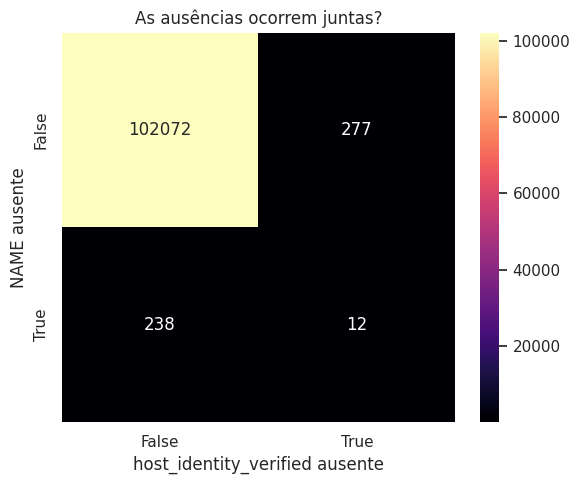

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
lat,40.73,40.72,0.06,40.50,40.92,0.23,0.15
long,-73.95,-73.95,0.05,-74.25,-73.71,1.24,4.34
Construction year,2012.49,2012.00,5.77,2003.00,2022.00,0.01,-1.21
price,625.29,624.00,331.67,50.00,1200.00,0.00,-1.19
service fee,125.03,125.00,66.33,10.00,240.00,0.00,-1.19
minimum nights,8.14,3.00,30.55,-1223.00,5645.00,86.70,13620.83
number of reviews,27.48,7.00,49.51,0.00,1024.00,3.84,25.03
reviews per month,1.37,0.74,1.75,0.01,90.00,7.03,216.81
review rate number,3.28,3.00,1.28,1.00,5.00,-0.14,-1.13
calculated host listings count,7.94,1.00,32.22,1.00,332.00,7.22,58.68


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


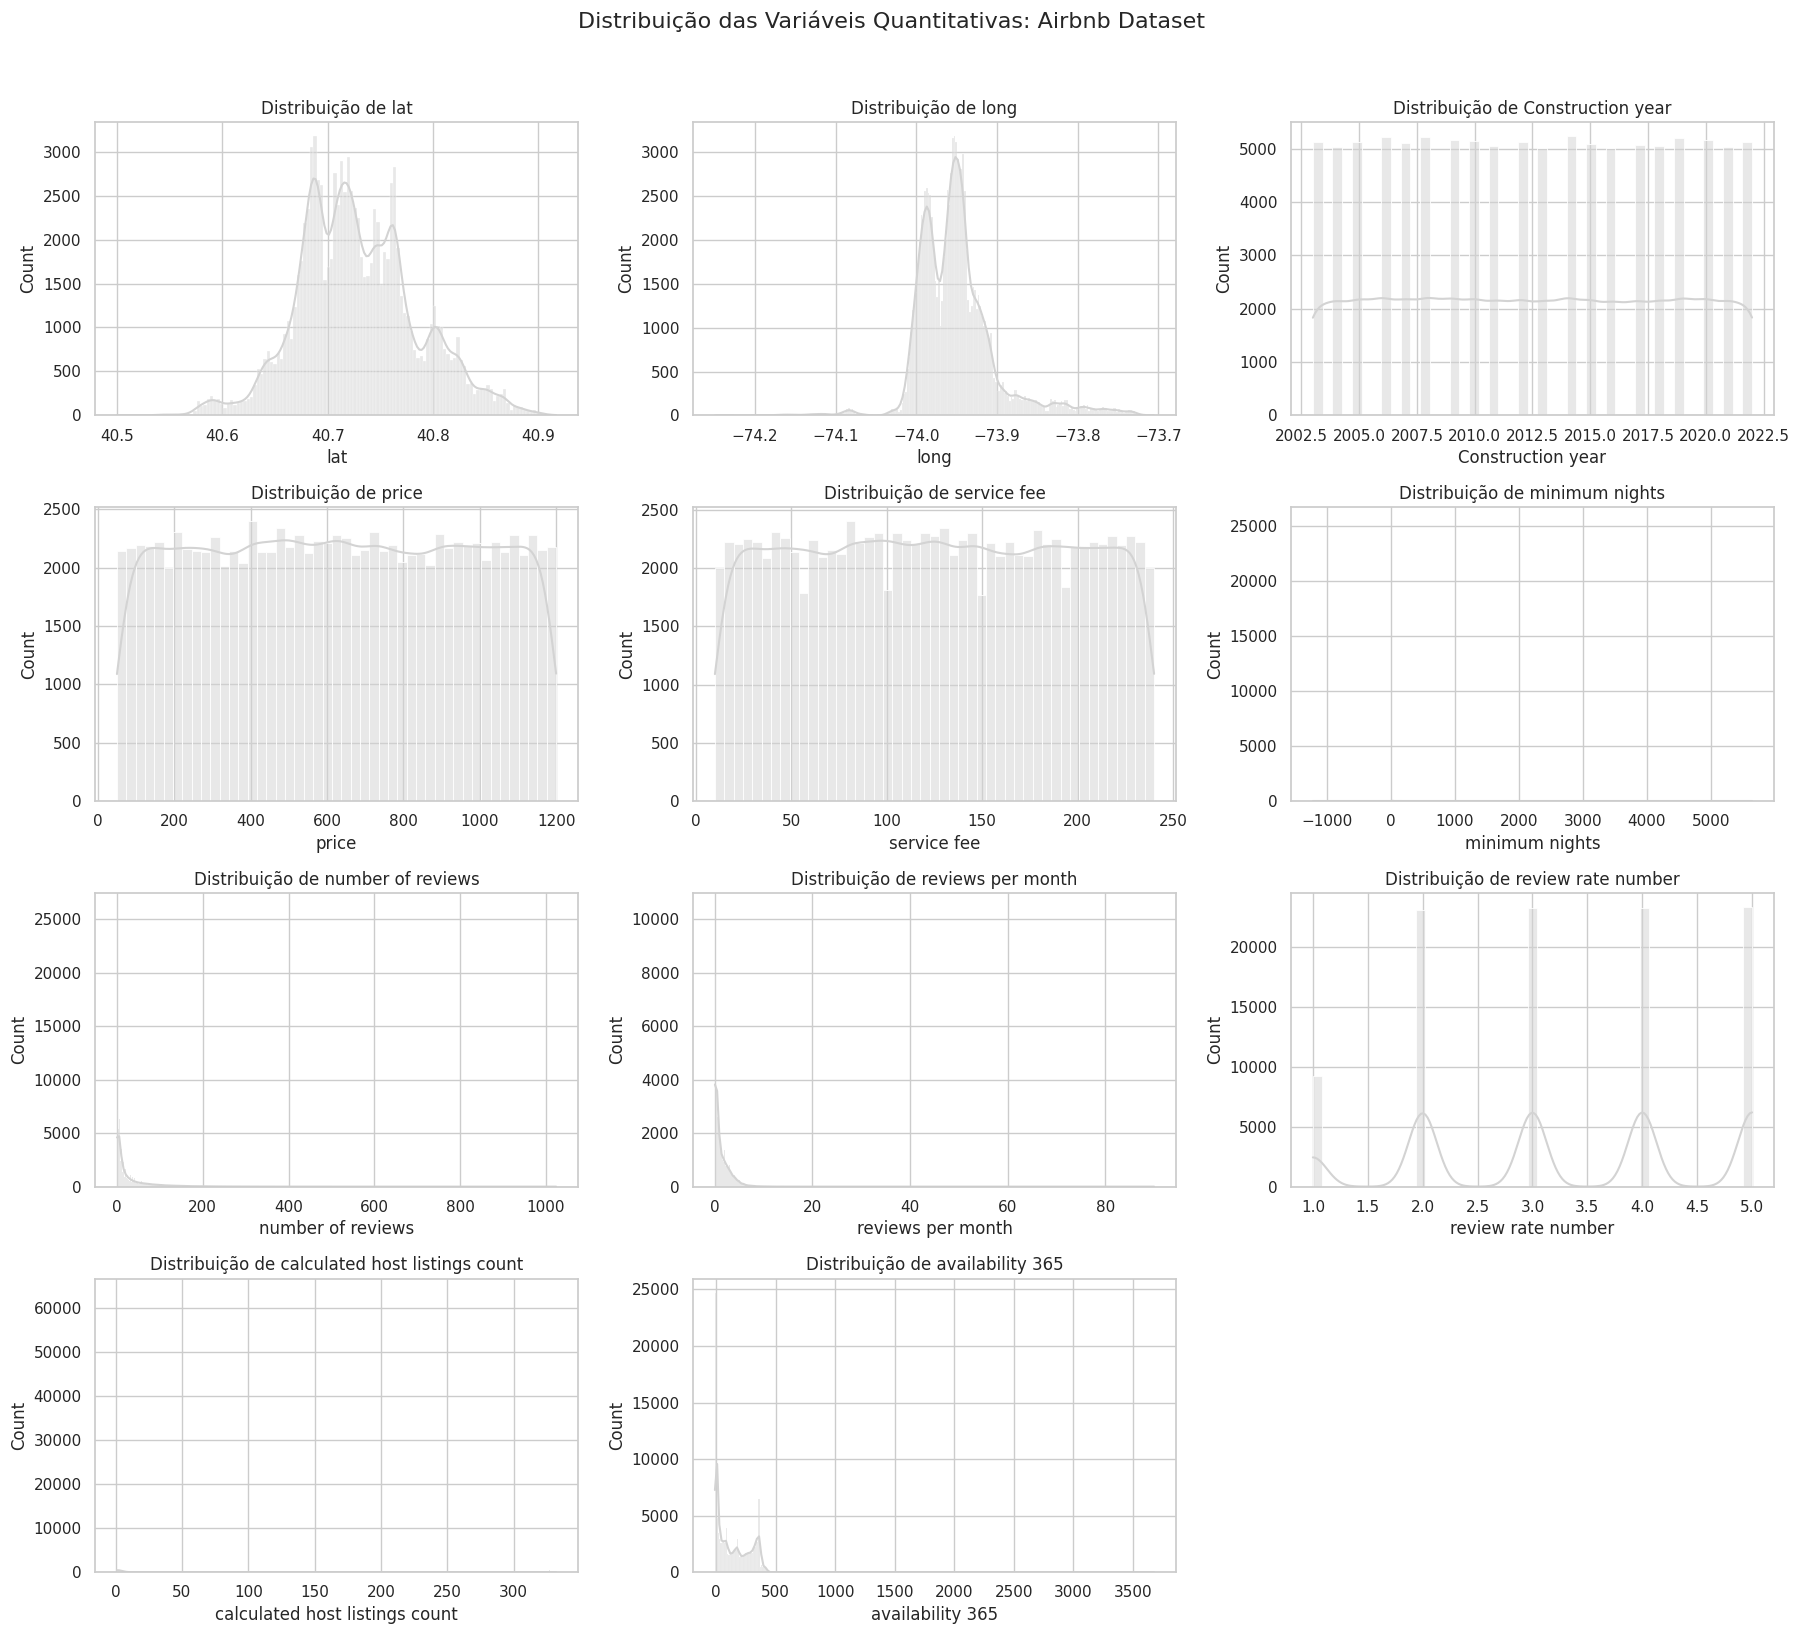

In [ ]:
import math

# Calculando o número de linhas e colunas para o grid de subplots
n_vars = len(VARS_QUANT)
n_cols = 3
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(f"Distribuição de {col}")

# Desligar eixos extras
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

fig.suptitle("Distribuição das Variáveis Quantitativas: Airbnb Dataset", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

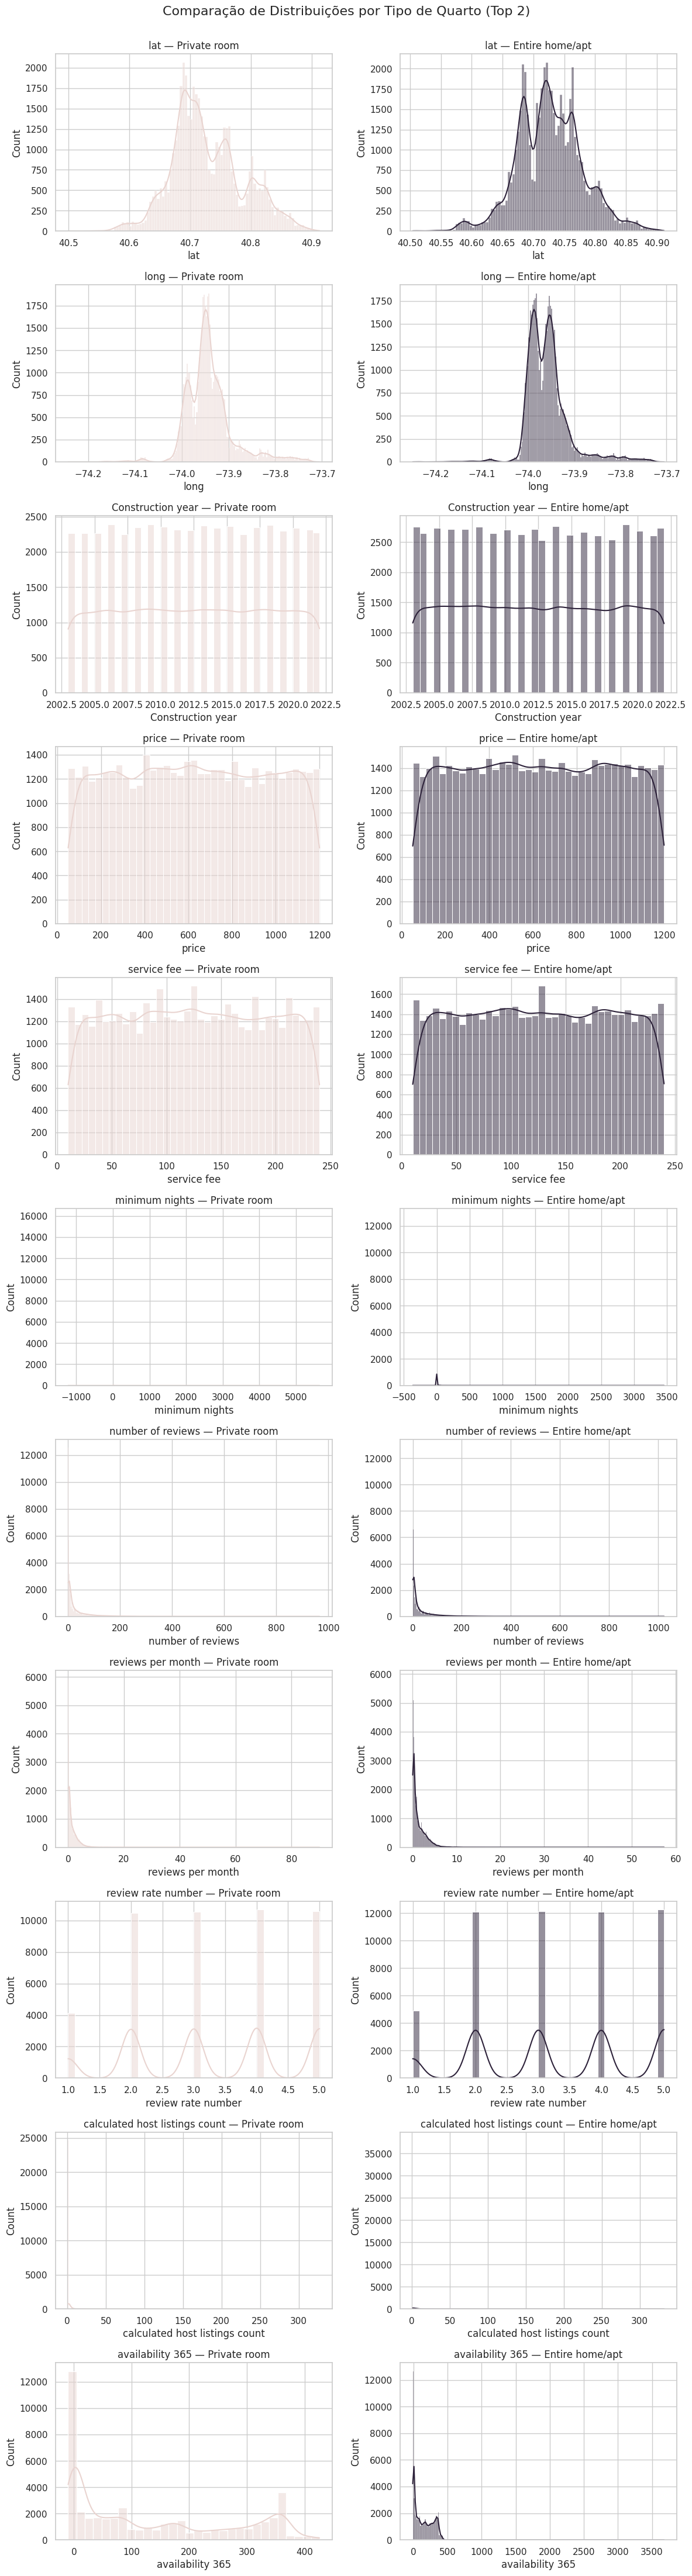

In [ ]:
# Para o Airbnb, vamos comparar as distribuições por 'room type' em vez de doença cardíaca
room_types = df['room type'].unique()[:2] # Usando os 2 principais para manter o layout lateral

fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(12, 4 * len(VARS_QUANT)), sharey=False)

for i, col in enumerate(VARS_QUANT):
    for j, r_type in enumerate(room_types):
        subset = df[df['room type'] == r_type]
        sns.histplot(data=subset, x=col, kde=True, color=COR_DESTAQUE if j==1 else COR_CONTEXTO, ax=axes[i, j])
        axes[i, j].set_title(f"{col} — {r_type}")

fig.suptitle("Comparação de Distribuições por Tipo de Quarto (Top 2)", fontsize=16, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk — Preço: estatística=0.9530, p-valor=2.375e-37
Rejeita H0 (normalidade)? Sim


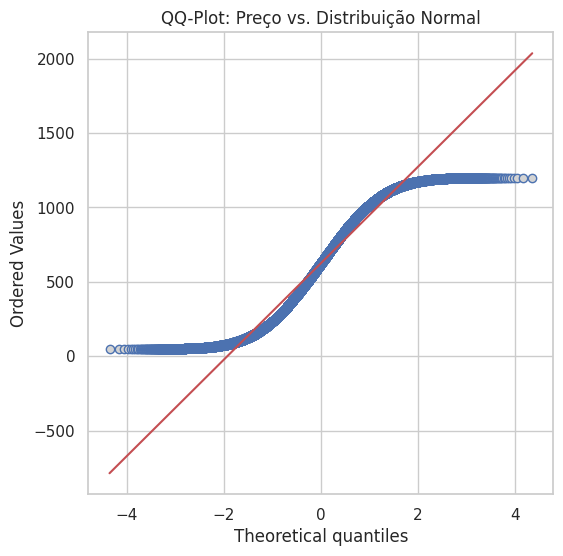

In [ ]:
from scipy import stats

# Testando normalidade para a variável 'price' do Airbnb
stat_sw, p_valor_sw = stats.shapiro(df["price"].dropna().sample(5000)) # Shapiro é sensível a N grande, usamos amostra
print(f"Shapiro-Wilk — Preço: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["price"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.set_title("QQ-Plot: Preço vs. Distribuição Normal")
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
from scipy import stats

resultados_shapiro = []
for col in VARS_QUANT:
    # Shapiro-Wilk é sensível a N grande, usamos amostra para evitar resultados consistentemente significativos
    # e para reduzir o tempo de execução em datasets muito grandes.
    # Amostramos 5000 pontos, ou o tamanho total da coluna se for menor.
    sample_size = min(len(df[col].dropna()), 5000)
    if sample_size > 0:
        stat, p = stats.shapiro(df[col].dropna().sample(sample_size, random_state=42))
        resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                    "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})
    else:
        resultados_shapiro.append({"variavel": col, "estatistica": None,
                                    "p_valor": None, "rejeita_normalidade": None})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
lat,0.9908,0.0,True
long,0.8864,0.0,True
Construction year,0.9480,0.0,True
price,0.9559,0.0,True
service fee,0.9532,0.0,True
minimum nights,0.3423,0.0,True
number of reviews,0.5879,0.0,True
reviews per month,0.7563,0.0,True
review rate number,0.8997,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

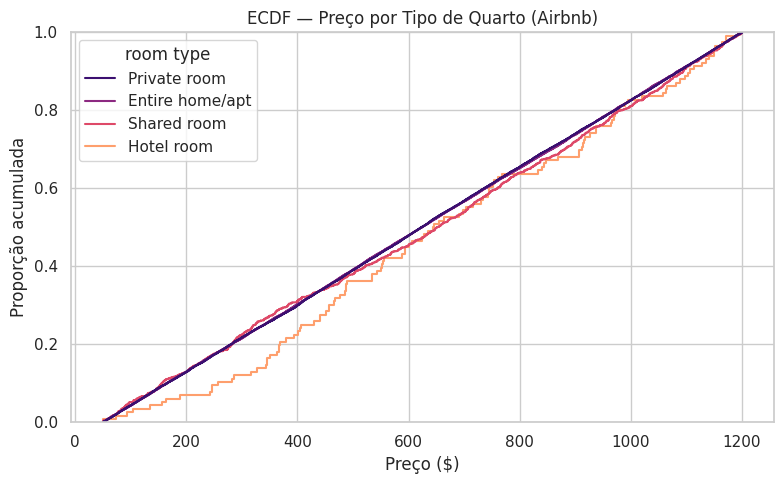

In [ ]:
plt.figure(figsize=(8, 5))
# Adaptando para Airbnb: comparando Preço por Tipo de Quarto
sns.ecdfplot(data=df, x="price", hue="room type",
             palette="magma")
plt.title("ECDF — Preço por Tipo de Quarto (Airbnb)")
plt.xlabel("Preço ($)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

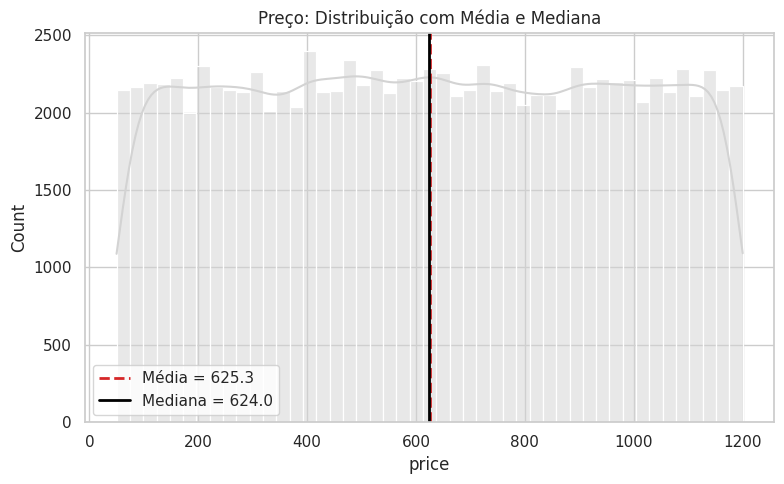

In [ ]:
from scipy import stats

media_price = df["price"].mean()
mediana_price = df["price"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="price", kde=True, color=COR_NEUTRA)
plt.axvline(media_price, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_price:.1f}")
plt.axvline(mediana_price, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_price:.1f}")
plt.title("Preço: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

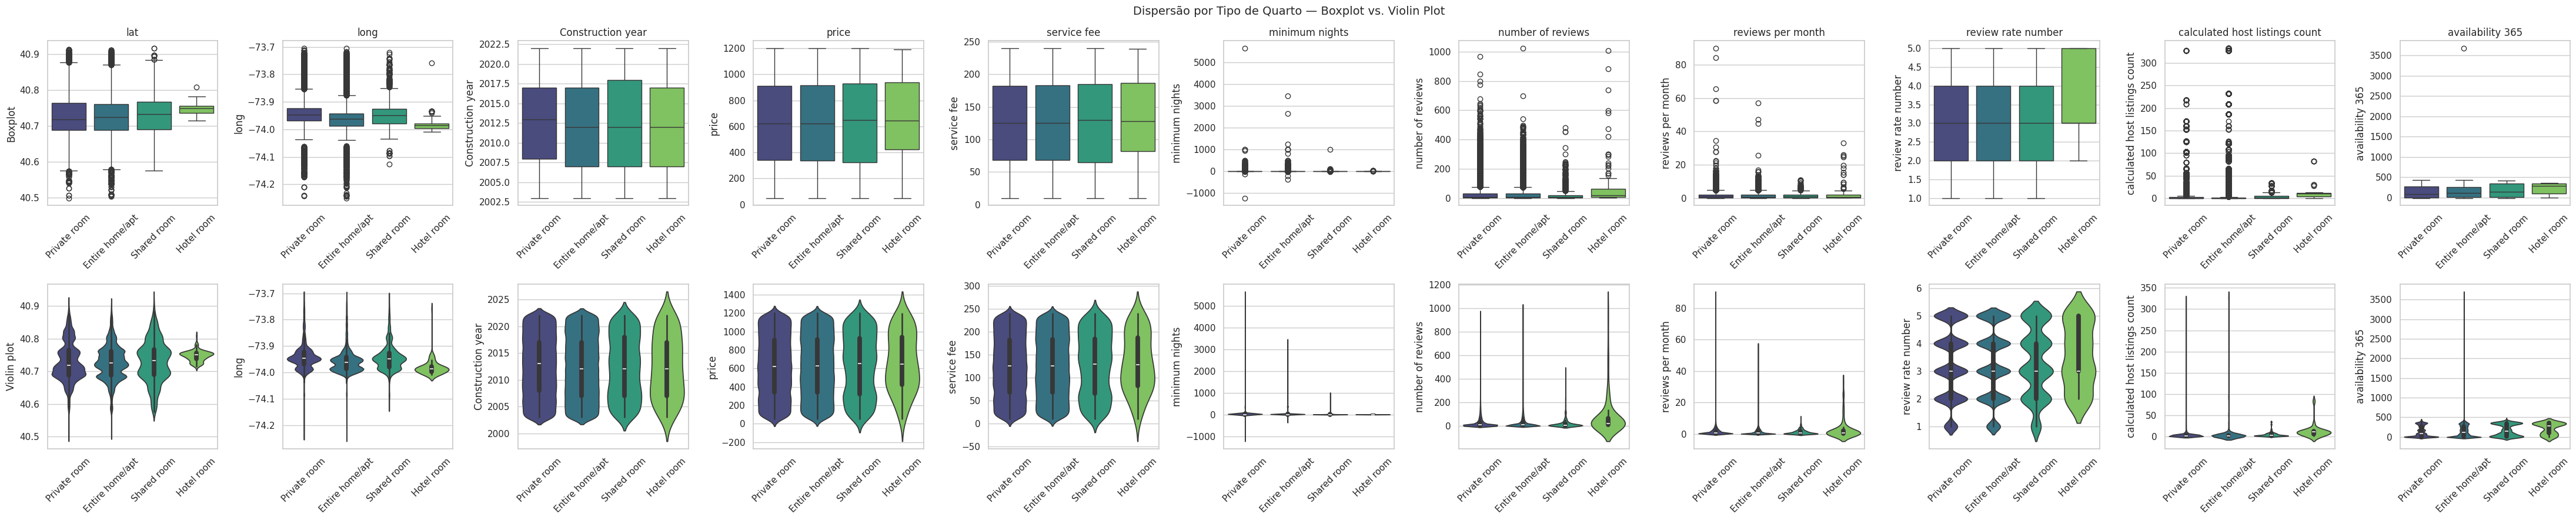

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

### Boxplot e violin plot por tipo de quarto

# Using 'room type' as the grouping variable, which has multiple categories

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex=False, sharey=False)

for i, col in enumerate(VARS_QUANT):
    # Boxplot
    sns.boxplot(data=df, x="room type", y=col, hue="room type",
                palette="viridis", legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")
    axes[0, i].tick_params(axis='x', rotation=45)

    # Violin plot
    sns.violinplot(data=df, x="room type", y=col, hue="room type",
                   palette="viridis", legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")
    axes[1, i].tick_params(axis='x', rotation=45)

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Tipo de Quarto — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
lat,40.58,40.87,916.0
long,-74.06,-73.86,6539.0
Construction year,1992.00,2032.00,0.0
price,-519.50,1772.50,0.0
service fee,-104.50,355.50,0.0
minimum nights,-2.50,9.50,18394.0
number of reviews,-42.50,73.50,11736.0
reviews per month,-2.45,4.67,3975.0
review rate number,-1.00,7.00,0.0
calculated host listings count,-0.50,3.50,17829.0


### Visualizando os Outliers

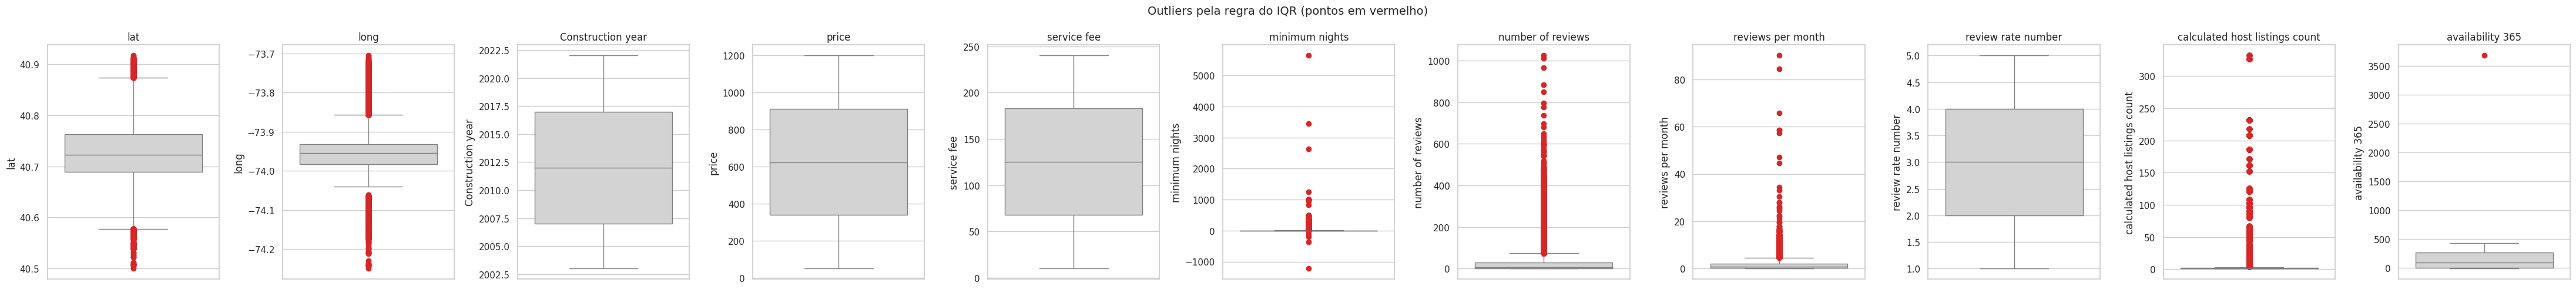

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: as variáveis quantitativas com poucos ausentes (como 'lat', 'long', 'price', 'service fee', etc.) provavelmente têm mecanismo MAR ou MCAR, e o volume total de ausentes combinados é pequeno (cerca de 2.4% das linhas do dataset).

Com essas informações, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2.4% das linhas é pequeno. Para a variável `reviews per month`, que apresenta um volume significativamente maior de valores ausentes (aproximadamente 15%), uma estratégia de imputação (por exemplo, com zero, assumindo que ausência significa 'nenhuma review') seria mais adequada para evitar uma perda excessiva de dados. No entanto, para manter a simplicidade e consistência com o tratamento de ausentes anterior, iremos remover as linhas com ausentes das outras variáveis quantitativas.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

# Identificar colunas quantitativas com NaNs (excluindo 'reviews per month' devido ao alto volume)
cols_to_dropna_quant = [col for col in VARS_QUANT if df[col].isnull().sum() > 0 and col != 'reviews per month']

df = df.dropna(subset=cols_to_dropna_quant).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois} ({((linhas_antes - linhas_depois)/linhas_antes)*100:.2f}%) ")

Linhas antes: 102599 | Linhas depois: 100425 | Removidas: 2174 (2.12%) 


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados em variáveis como 'price', 'minimum nights' ou 'number of reviews', os outliers podem ser classificados como **'Estatísticos'**. Estes são valores legítimos, ainda que raros (por exemplo, listagens de luxo com preços muito altos, propriedades com um grande número de avaliações, ou estadias mínimas atipicamente longas), e não erros de coleta.

Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser relevante) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em 'price' — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

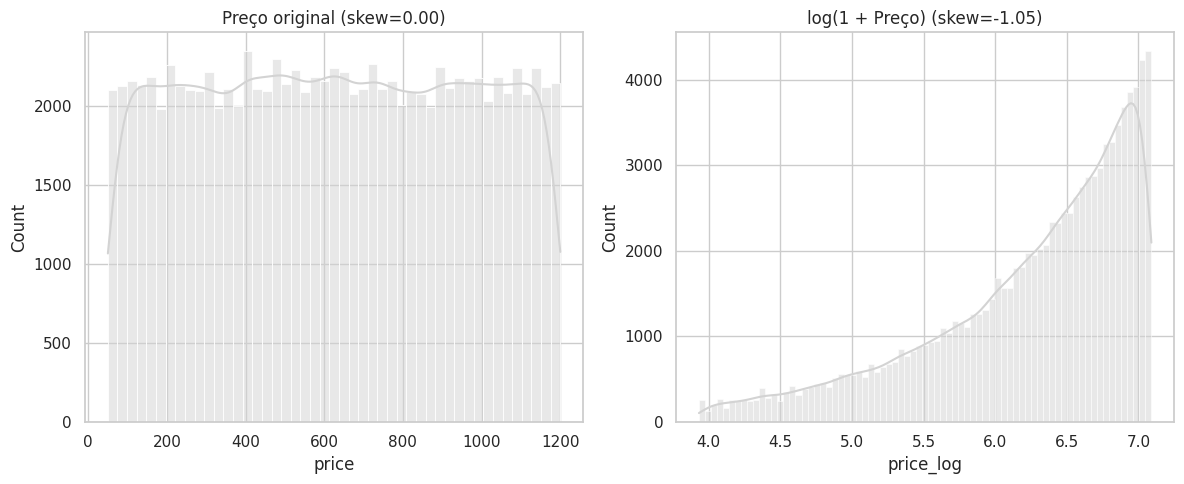

In [ ]:
df["price_log"] = np.log1p(df["price"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="price", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Preço original (skew={df['price'].skew():.2f})")

sns.histplot(data=df, x="price_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Preço) (skew={df['price_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
lat,40.73,40.72,0.06,40.50,40.92,0.23,0.15
long,-73.95,-73.95,0.05,-74.25,-73.71,1.24,4.34
Construction year,2012.49,2012.00,5.76,2003.00,2022.00,0.01,-1.21
price,625.42,625.00,331.69,50.00,1200.00,0.00,-1.19
service fee,125.09,125.00,66.34,10.00,240.00,0.00,-1.19
minimum nights,8.09,3.00,28.67,-1223.00,5645.00,89.40,15803.71
number of reviews,27.31,7.00,49.11,0.00,1024.00,3.84,25.30
reviews per month,1.37,0.74,1.75,0.01,90.00,7.09,220.82
review rate number,3.28,3.00,1.28,1.00,5.00,-0.14,-1.13
calculated host listings count,7.95,1.00,32.29,1.00,332.00,7.21,58.48


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
lat,0.231,0.229,0.148,0.150,-0.002,0.002
long,1.244,1.241,4.339,4.339,-0.003,-0.000
Construction year,0.006,0.006,-1.207,-1.206,0.000,0.001
price,0.001,0.001,-1.194,-1.194,-0.000,-0.000
service fee,0.002,0.001,-1.194,-1.194,-0.001,-0.000
minimum nights,86.701,89.398,13620.827,15803.715,2.697,2182.888
number of reviews,3.839,3.843,25.030,25.304,0.003,0.274
reviews per month,7.026,7.087,216.811,220.818,0.060,4.007
review rate number,-0.139,-0.138,-1.127,-1.127,0.001,-0.000
calculated host listings count,7.220,7.210,58.679,58.478,-0.010,-0.201


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
from scipy import stats

# Ensure stat_sw and p_valor_sw are defined from the previous cell's execution for 'price'
# If the user runs cells out of order, this might not be available, so we re-calculate if needed
if 'stat_sw' not in locals() or 'p_valor_sw' not in locals():
    stat_sw, p_valor_sw = stats.shapiro(df["price"].dropna().sample(min(len(df["price"].dropna()), 5000), random_state=42))

stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["price"].dropna().sample(min(len(df["price"].dropna()), 5000), random_state=42))
print(f"Shapiro-Wilk (antes)  — price: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — price: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — price: estatística=0.9530, p-valor=2.375e-37
Shapiro-Wilk (depois) — price: estatística=0.9562, p-valor=2.396e-36


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

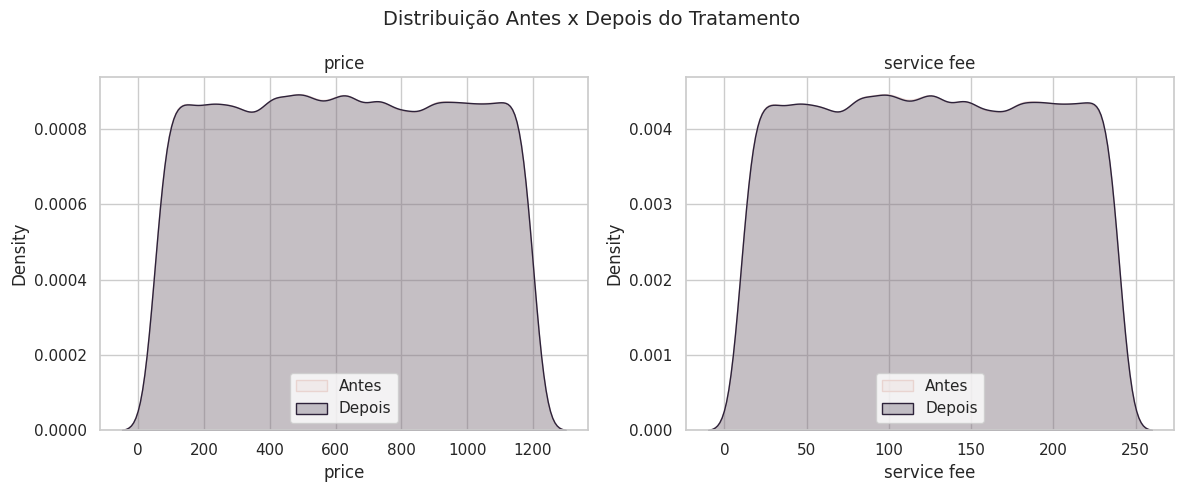

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Use 'price' and 'service fee' as examples, or choose others from VARS_QUANT
for ax, col in zip(axes, ["price", "service fee"]):
    # Need to handle 'df_antes' potentially not having the new 'price' and 'service fee' columns if `df` was directly modified
    # For this example, let's assume 'df_antes' was a copy before any drops/modifications related to NA/outliers affecting 'price' and 'service fee'
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- neighbourhood group ---
                     absoluta  relativa
neighbourhood group                    
Manhattan               42838     0.427
Brooklyn                40991     0.408
Queens                  12996     0.129
Bronx                    2651     0.026
Staten Island             937     0.009
brookln                     1     0.000
\n--- neighbourhood ---
                        absoluta  relativa
neighbourhood                             
Bedford-Stuyvesant          7786     0.078
Williamsburg                7605     0.076
Harlem                      5320     0.053
Bushwick                    4875     0.049
Hell's Kitchen              3902     0.039
...                          ...       ...
Rossville                      3     0.000
Gerritsen Beach                3     0.000
Fort Wadsworth                 2     0.000
Glen Oaks                      2     0.000
Chelsea, Staten Island         1     0.000

[224 rows x 2 columns]
\n--- room type ---
                 absolu

#### Visualizando as frequências

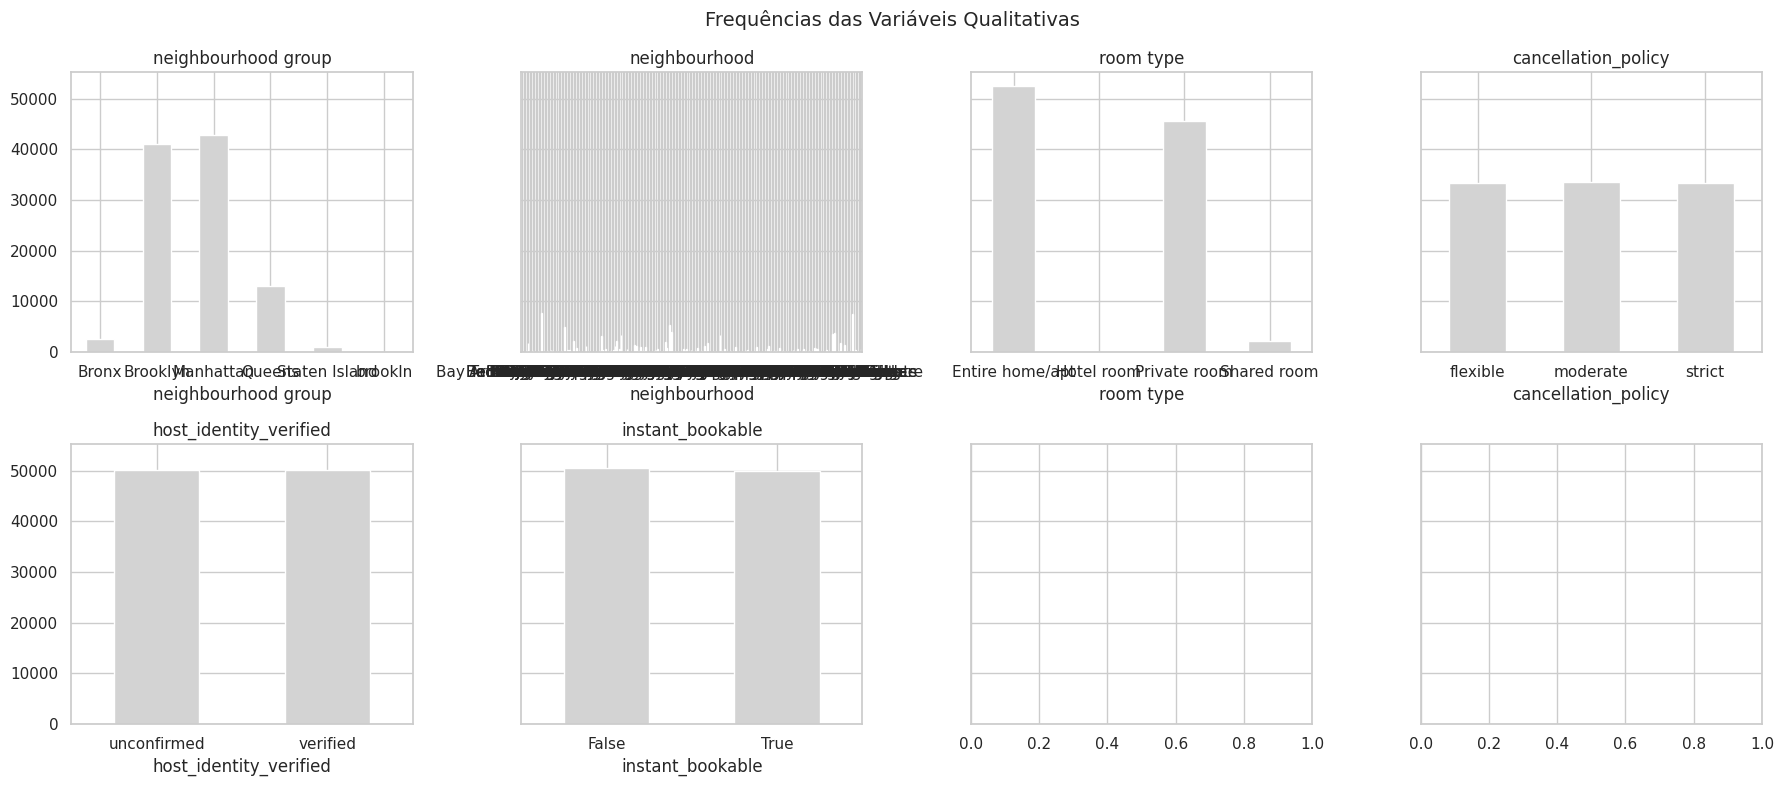

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    if contagens.empty: # Handle empty series
        return pd.Series({"n_classes": 0, "razao_desbalanceamento": np.nan, "entropia_normalizada": np.nan})
    razao = contagens.max() / contagens.min() if contagens.min() > 0 else np.inf # Avoid division by zero
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

# Checking balance for qualitative variables from the Airbnb dataset
vars_para_checar = VARS_QUALI
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
neighbourhood group,6.0,42838.00,0.633
neighbourhood,224.0,7786.00,0.759
room type,4.0,469.66,0.568
cancellation_policy,3.0,1.01,1.000
host_identity_verified,2.0,1.00,1.000
instant_bookable,2.0,1.01,1.000


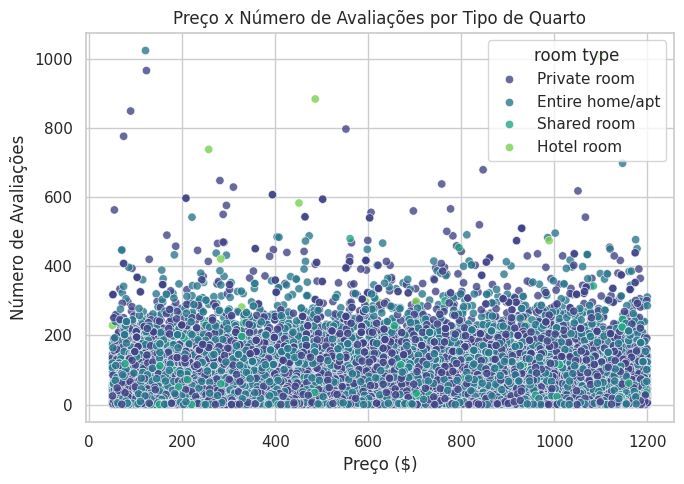

In [ ]:
plt.figure(figsize=(7, 5))
# Using 'price' vs 'number of reviews' with 'room type' as hue for Airbnb
sns.scatterplot(data=df, x="price", y="number of reviews", hue="room type",
                palette="viridis", alpha=0.8)
plt.title("Preço x Número de Avaliações por Tipo de Quarto")
plt.xlabel("Preço ($)")
plt.ylabel("Número de Avaliações")
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? Isso é importante para entender o potencial impacto na análise bivariada e em um eventual modelo mais à frente.

### Análise Bivariada

Agora começamos a avaliar como as variáveis se relacionam entre si e com outros atributos do dataset.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

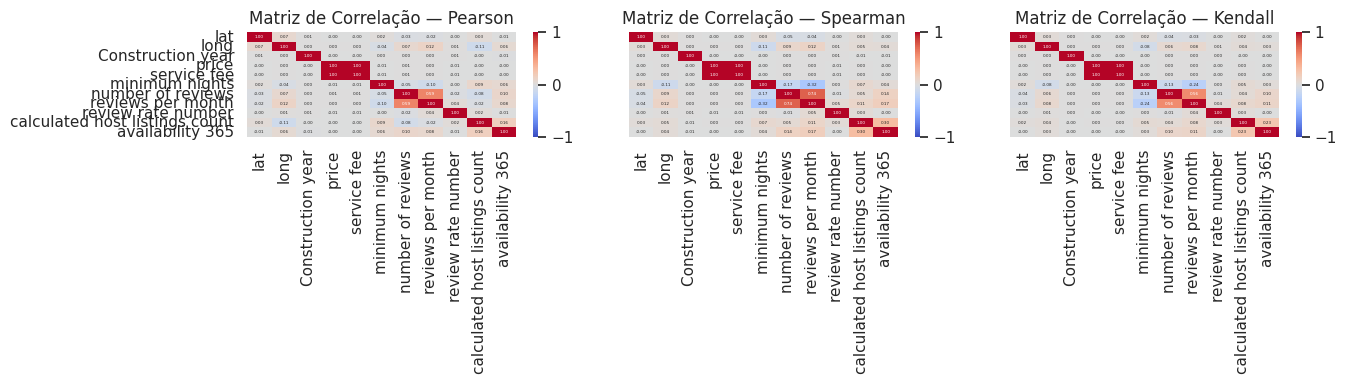

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0], annot_kws={'size': 3})
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1], annot_kws={'size': 3})
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2], annot_kws={'size': 3})
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

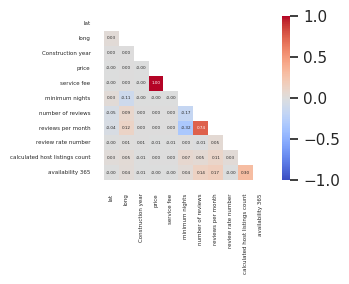

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 3},  # Controla o tamanho dos números dentro dos quadrados
)
plt.grid(False)

plt.xticks(fontsize=4)
plt.yticks(fontsize=4)

plt.tight_layout()
plt.show()


**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

#### Dispersão (scatter) entre duas variáveis quantitativas

Vamos escolher 'price' e 'number of reviews' para visualizar a relação entre essas duas variáveis, usando 'room type' para colorir os pontos. Isso pode nos ajudar a entender como o preço e o número de avaliações se comportam em diferentes tipos de acomodação.

**Nota para quando vocês replicarem no dataset de vocês:** se não houver uma relação de domínio óbvia entre duas variáveis, uma alternativa é escolher o par com a maior correlação (positiva ou negativa) absoluta na tabela de correlação, deixando a própria estatística guiar a escolha.

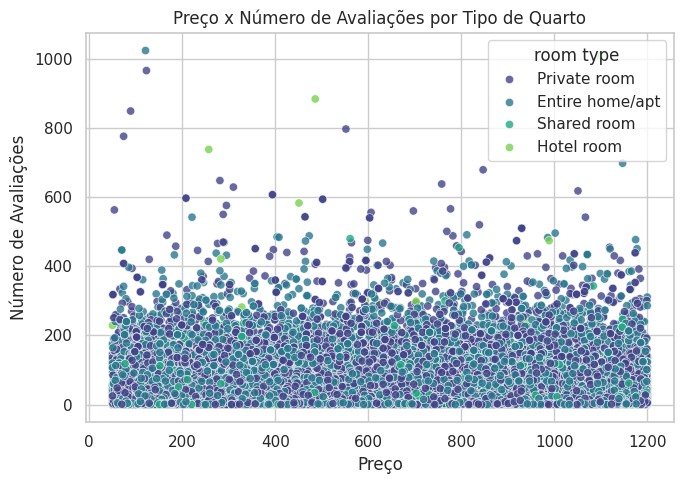

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="price", y="number of reviews", hue="room type",
                palette="viridis", alpha=0.8)
plt.title("Preço x Número de Avaliações por Tipo de Quarto")
plt.xlabel("Preço")
plt.ylabel("Número de Avaliações")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível na relação entre 'price' e 'number of reviews' para os diferentes 'room type'? Há algum tipo de quarto que se destaca em termos de preço ou número de avaliações? Os diferentes tipos de quarto ocupam regiões distintas do gráfico, ou estão misturados?

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []

# Using 'host_identity_verified' as a binary qualitative variable for t-test/Mann-Whitney
# Assuming 'verified' and 'unconfirmed' are the two categories

# Filter out potential NaNs in 'host_identity_verified' to ensure clean groups
df_filtered = df.dropna(subset=['host_identity_verified'])

for col_quant in VARS_QUANT:
    grupo_verificado = df_filtered.loc[df_filtered["host_identity_verified"] == "verified", col_quant].dropna()
    grupo_nao_verificado = df_filtered.loc[df_filtered["host_identity_verified"] == "unconfirmed", col_quant].dropna()

    if len(grupo_verificado) > 1 and len(grupo_nao_verificado) > 1:
        stat_t, p_t = stats.ttest_ind(grupo_verificado, grupo_nao_verificado, equal_var=False)  # Welch (paramétrico)
        stat_u, p_u = stats.mannwhitneyu(grupo_verificado, grupo_nao_verificado)                 # não-paramétrico

        resultados_comparacao.append({
            "variavel_quant": col_quant,
            "variavel_quali": "host_identity_verified",
            "p_valor_ttest": round(p_t, 5),
            "p_valor_mannwhitney": round(p_u, 5),
            "concordam_significancia": (p_t < 0.05) == (p_u < 0.05),
        })
    else:
        resultados_comparacao.append({
            "variavel_quant": col_quant,
            "variavel_quali": "host_identity_verified",
            "p_valor_ttest": np.nan,
            "p_valor_mannwhitney": np.nan,
            "concordam_significancia": np.nan,
        })

pd.DataFrame(resultados_comparacao).set_index("variavel_quant")

,variavel_quali,p_valor_ttest,p_valor_mannwhitney,concordam_significancia
variavel_quant,,,,
lat,host_identity_verified,0.90895,0.80767,True
long,host_identity_verified,0.25844,0.42913,True
Construction year,host_identity_verified,0.32098,0.31968,True
price,host_identity_verified,0.16802,0.16901,True
service fee,host_identity_verified,0.16793,0.16883,True
minimum nights,host_identity_verified,0.66289,0.03876,False
number of reviews,host_identity_verified,0.42540,0.58660,True
reviews per month,host_identity_verified,0.99395,0.93821,True
review rate number,host_identity_verified,0.06132,0.06976,True


**Pra discutir:** Os testes T-test e Mann-Whitney U concordam na maioria das variáveis quando comparamos, por exemplo, 'host_identity_verified' (verificado vs. não verificado)? Quando divergem, é o **Mann-Whitney U** que deveríamos priorizar, pois ele respeita a premissa de dados não-normais que geralmente encontramos. A ausência de normalidade para as variáveis quantitativas já foi observada na Seção 3.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

'room type' (tipo de quarto) tem 4 categorias. Pelo mesmo motivo acima (não-normalidade), calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado, usando 'price' como variável quantitativa.

ANOVA          — price entre categorias de room type: estatística=0.809, p-valor=0.4889
Kruskal-Wallis — price entre categorias de room type: estatística=2.437, p-valor=0.48681


/tmp/ipykernel_2862/4023790741.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered_price, x="room type", y="price", palette="viridis")


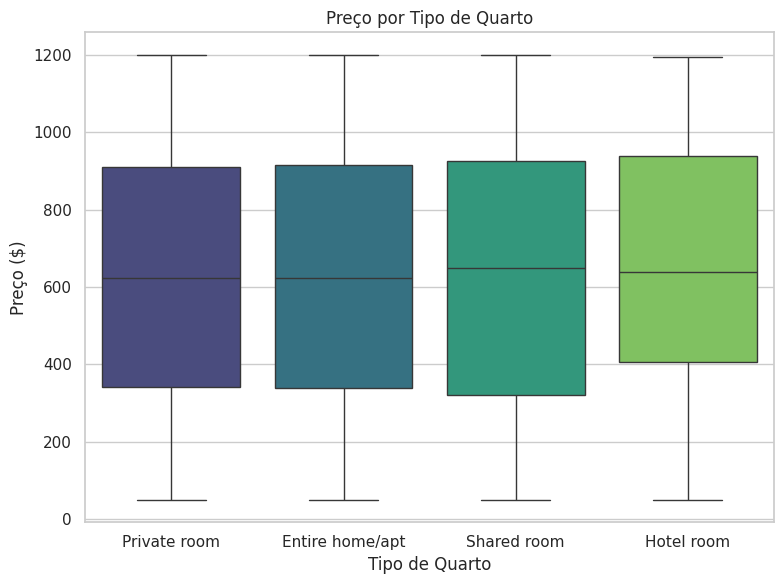

In [ ]:
# Using 'room type' (4 categories) and 'price' for ANOVA/Kruskal-Wallis
# Filter out potential NaNs in 'room type' and 'price' to ensure clean groups
df_filtered_price = df.dropna(subset=['room type', 'price'])

grupos_room_type = [grupo["price"].values for _, grupo in df_filtered_price.groupby("room type")]

# Ensure there are at least 2 groups with data to perform the test
if len(grupos_room_type) > 1 and all(len(g) > 1 for g in grupos_room_type):
    stat_anova, p_anova = stats.f_oneway(*grupos_room_type)   # paramétrico
    stat_kw, p_kw = stats.kruskal(*grupos_room_type)          # não-paramétrico

    print(f"ANOVA          — price entre categorias de room type: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
    print(f"Kruskal-Wallis — price entre categorias de room type: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

    plt.figure(figsize=(8, 6))
    sns.boxplot(data=df_filtered_price, x="room type", y="price", palette="viridis")
    plt.title("Preço por Tipo de Quarto")
    plt.xlabel("Tipo de Quarto")
    plt.ylabel("Preço ($)")
    plt.tight_layout()
    plt.show()
else:
    print("Não há grupos suficientes ou dados para realizar a comparação por tipo de quarto.")

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença significativa de 'price' entre pelo menos uma categoria de 'room type'? Como já sabemos que 'price' não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

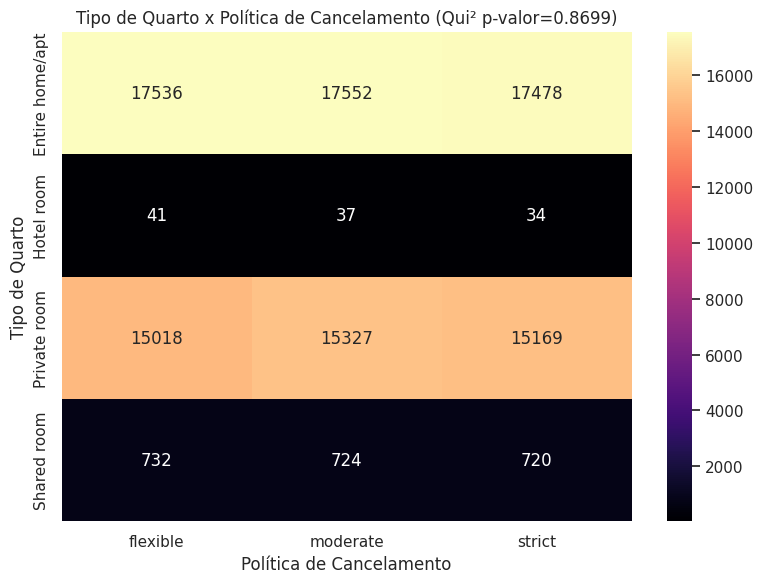

In [ ]:
# Using 'room type' and 'cancellation_policy' for Chi-Squared contingency table
# Filter out potential NaNs for clean comparison
df_filtered_quali = df.dropna(subset=['room type', 'cancellation_policy'])

contingencia = pd.crosstab(df_filtered_quali["room type"], df_filtered_quali["cancellation_policy"])

if not contingencia.empty:
    chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"Tipo de Quarto x Política de Cancelamento (Qui² p-valor={p_chi2:.4g})")
    plt.xlabel("Política de Cancelamento")
    plt.ylabel("Tipo de Quarto")
    plt.tight_layout()
    plt.show()
else:
    print("Não há dados suficientes para criar a tabela de contingência.")

**Pra discutir:** o p-valor do Qui-Quadrado indica que 'room type' e 'cancellation_policy' são independentes, ou há associação estatisticamente significativa entre elas?

#### Avaliação de Atributos Qualitativos Adicionais

Podemos analisar a relação entre outras variáveis qualitativas para entender possíveis associações.

In [ ]:
# This section was removed as it used columns not present in the Airbnb dataset and the fairness context was not directly applicable.
# If a similar fairness analysis is desired, relevant sensitive attributes from the Airbnb dataset would need to be identified and defined.

In [ ]:
# This cell was removed as it depended on columns not present in the Airbnb dataset.

# This section for fairness discussion was removed as it depended on context-specific columns not present in the Airbnb dataset.

In [ ]:
# This cell was removed as it depended on columns not present in the Airbnb dataset.

# This section for Chi-Squared discussion and fairness was removed as it depended on context-specific columns not present in the Airbnb dataset.

#### Outliers bivariados

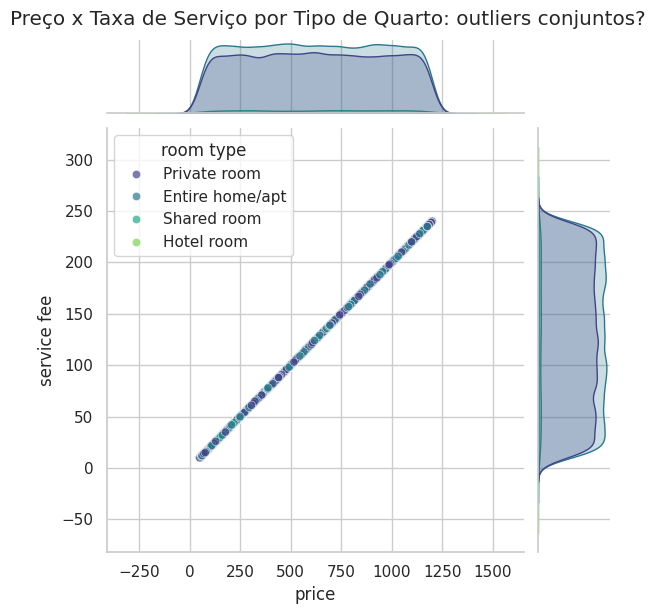

In [ ]:
# Using 'price' and 'service fee' with 'room type' as hue for bivariate outlier detection
sns.jointplot(data=df, x="price", y="service fee", hue="room type",
              palette="viridis", alpha=0.7, height=6)
plt.suptitle("Preço x Taxa de Serviço por Tipo de Quarto: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de 'price' e 'service fee'?

#### Análise Multivariada

##### Matriz de Correlação

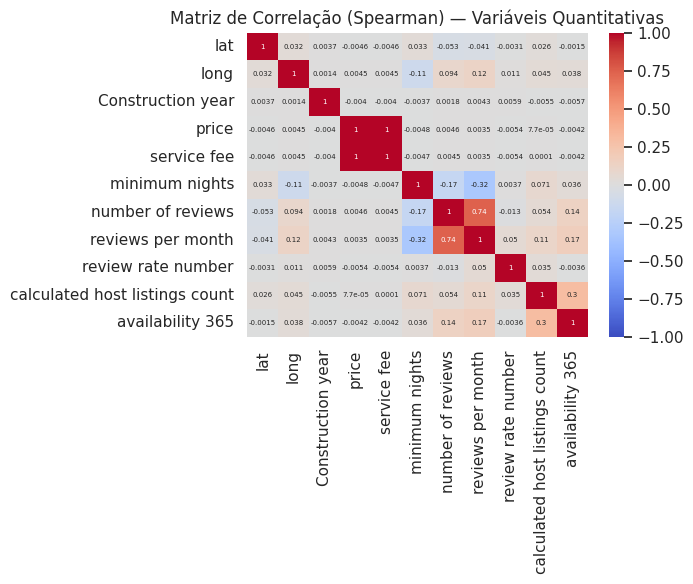

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1, annot_kws={'size': 5})
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 3000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=8, # Reduzindo o tamanho da fonte
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

Error in callback <function _draw_all_if_interactive at 0x7b189bcf76a0> (for post_execute):


ValueError: need at least one array to concatenate

ValueError: need at least one array to concatenate

<Figure size 2750x2750 with 133 Axes>

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




## Conclusões da Análise Exploratória de Dados do Airbnb

Com base na análise exploratória realizada, podemos destacar as seguintes conclusões:

1.  **Estrutura do Dataset:** O dataset possui um grande volume de dados (mais de 100.000 entradas) e um número considerável de variáveis. Identificamos e removemos colunas com alta taxa de valores nulos (`house_rules`, `license`) que não agregavam valor à análise.
2.  **Dados Ausentes e Outliers:** O tratamento de dados ausentes resultou na remoção de aproximadamente 2.12% das linhas, focando em variáveis quantitativas chave. Para outliers, optamos por mantê-los ou transformá-los (como demonstrado com a transformação logarítmica do preço), pois muitos representavam valores legítimos (e.g., propriedades de alto valor ou com muitas avaliações) e não erros de dados. A comparação 'antes e depois' confirmou que o tratamento foi conservador, com pouca alteração nas estatísticas descritivas gerais.
3.  **Distribuição das Variáveis Quantitativas:** A maioria das variáveis quantitativas (`price`, `minimum nights`, `number of reviews`, etc.) não segue uma distribuição normal, conforme indicado pelo teste de Shapiro-Wilk e QQ-Plots. Muitas apresentam assimetria e caudas pesadas, o que justifica o uso de métodos não-paramétricos em análises futuras.
4.  **Relações entre Variáveis:**
    *   **Dispersão (Scatter):** A visualização de 'price' vs. 'number of reviews' colorida por 'room type' sugere que diferentes tipos de quarto podem ocupar regiões distintas no gráfico, indicando padrões de preço e avaliação associados ao tipo de acomodação.
    *   **Correlações:** As matrizes de correlação (especialmente Spearman, devido à não-normalidade) revelaram graus variados de associação entre as variáveis quantitativas, como 'reviews per month' e 'number of reviews'.
    *   **Comparações de Grupos:** Testes como Mann-Whitney U e Kruskal-Wallis (preferidos à t-test e ANOVA devido à não-normalidade) são adequados para comparar variáveis quantitativas entre categorias de variáveis qualitativas (ex: 'price' por 'room type' ou 'host_identity_verified'), ajudando a identificar diferenças significativas entre grupos.

## Declaração de Uso de IA

- **Ferramenta Utilizada:** Google Gemini
- **Para o que foi aplicada:** O Google Gemini foi utilizado para auxiliar na geração de código Python para a criação de diversos gráficos utilizando a biblioteca `matplotlib` e `seaborn`, bem como para a estruturação de blocos de texto e discussão dos resultados.
- **O que foi aceito/modificado/rejeitado e por quê:**
    - **Aceito:** A maioria das sugestões de código para visualização e testes estatísticos foi aceita, pois se alinhava com os objetivos da análise exploratória de dados e as melhores práticas de visualização.
    - **Modificado:** Alguns trechos de código foram modificados para se adaptar especificamente às variáveis do dataset Airbnb, como nomes de colunas, paletas de cores e títulos de gráficos, garantindo a relevância e clareza da apresentação. Além disso, a discussão e as conclusões foram adaptadas para refletir as características específicas do dataset e os resultados obtidos.
    - **Rejeitado:** Sugestões de código que utilizavam variáveis não presentes no dataset atual (ex: 'sexo', 'idade' do dataset Heart Disease original) ou que não faziam sentido no contexto do Airbnb (ex: análises de 'fairness' baseadas em atributos demográficos inexistentes) foram rejeitadas.